# Clustering the LCA curves (from saved results)

Runs on the CSVs that `LCA_Creativity.ipynb` already wrote to `results/k5_clean/`. **No model runs and no
need to re-run the main notebook**: open this one and run it top to bottom (a few seconds).

**Question:** if we only look at the *shape* of each text's LCA curve (variance, STD, jumpiness...), and never
tell the algorithm which texts are factual or creative, do the texts split into those two groups by themselves?

**Steps**
1. Turn each text's curve into a few numbers (features)
2. Average the 3 models: they follow almost the same curve, so this cuts noise
3. Cluster with **KMeans** and **hierarchical (Ward)**, k = 2 (and k = 3)
4. Score the clusters against the true labels: **ARI** (1 = perfect, 0 = no better than random) and **purity**
5. Repeat with variance/STD only, on nouns only, per model, and against a model-confidence baseline

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")   # avoids sklearn's KMeans memory-leak warning on Windows
import sys
import warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "lca_core.py").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from lca_core import CURVE_FEATURE_NAMES, feature_table, load_results

RESULTS = ROOT / "src" / "note_books" / "LCA-Yoav" / "results" / "k5_clean"
FIG_DIR = RESULTS / "clustering"
FIG_DIR.mkdir(exist_ok=True)

warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")

LCA_FEATS = list(CURVE_FEATURE_NAMES)              # curve shape only
VAR_FEATS = ["var", "std", "mean_abs_jump", "max_abs_jump", "direction_changes"]  # spread / jumpiness only
CONF_FEATS = ["actual_word_prob", "cand_mass"]     # how sure the model was
COLORS = {"factual": "#2a6fdb", "creative": "#e0662f"}

data = load_results(RESULTS)
print({m: len(t) for m, t in data.items()}, "texts per model")

{'EleutherAI_pythia-410m': 18, 'gpt2-medium': 18, 'Qwen_Qwen2.5-1.5B': 18} texts per model


## 1. Features per text
Each curve gets 6 shape numbers (from `lca_core.curve_features`):

| feature | meaning |
|---|---|
| `mean` | average LCA height (level) |
| `var` / `std` | variance and standard deviation of the height (spread) |
| `mean_abs_jump` | average change between consecutive words |
| `max_abs_jump` | largest single change |
| `share_ge_8` | share of points with height >= 8 |
| `direction_changes` | how often the curve flips up/down (converging/diverging) |

Plus two model-confidence columns, used only in run C: `actual_word_prob` (mean P(real word)) and
`cand_mass` (mean total probability of the top-k guesses).

In [2]:
def per_text(pos=None):
    """Feature table averaged over the 3 models: one row per text."""
    ft = feature_table(data, pos=pos)
    ft["std"] = np.sqrt(ft["var"])
    return ft.groupby(["text", "kind"], as_index=False)[LCA_FEATS + ["std"] + CONF_FEATS + ["verb_frac"]].mean()


texts_all = per_text()
texts_all.round(3).sort_values("kind")

,text,kind,mean,var,mean_abs_jump,max_abs_jump,share_ge_8,direction_changes,std,actual_word_prob,cand_mass,verb_frac
0,creative_harry_potter,creative,4.797,4.263,2.668,6.333,0.117,0.724,2.060,0.282,0.418,0.370
9,creative_jokes_for_all_occasions,creative,5.434,4.315,2.431,8.333,0.146,0.783,2.076,0.183,0.350,0.330
7,creative_hp7,creative,4.496,4.769,2.468,9.333,0.121,0.783,2.182,0.124,0.301,0.549
6,creative_hp6,creative,4.764,6.283,2.902,10.667,0.109,0.791,2.505,0.110,0.271,0.535
5,creative_hp5,creative,4.827,5.096,2.859,7.667,0.133,0.822,2.257,0.124,0.285,0.462
8,creative_jokes_2,creative,5.049,5.049,2.554,9.667,0.130,0.802,2.246,0.126,0.301,0.389
3,creative_hp3,creative,4.456,5.122,2.738,7.667,0.133,0.775,2.263,0.153,0.331,0.536
2,creative_hp2,creative,4.561,5.203,2.749,7.333,0.123,0.793,2.281,0.152,0.321,0.518
1,creative_hp1,creative,4.879,5.543,2.806,7.000,0.186,0.760,2.354,0.151,0.316,0.493
4,creative_hp4,creative,4.590,5.255,2.706,8.333,0.159,0.796,2.291,0.158,0.365,0.547


## 2. Clustering helpers
Features are standardised first (mean 0, std 1), so a feature with large numbers (like `var`) doesn't dominate.

In [3]:
def short(name):
    return name.replace("factual_wiki_", "wiki:").replace("creative_", "")


def purity(true, pred):
    """Share of texts that are in a cluster whose majority kind matches theirs."""
    tab = pd.crosstab(pred, true)
    return tab.max(axis=1).sum() / tab.values.sum()


def cluster(table, feats, k=2, title="", label_col="kind", name_col="text"):
    X = StandardScaler().fit_transform(table[feats])
    y = table[label_col].to_numpy()
    km = KMeans(n_clusters=k, n_init=50, random_state=0).fit_predict(X)
    ward = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)

    scores = pd.DataFrame({
        "ARI": [adjusted_rand_score(y, km), adjusted_rand_score(y, ward)],
        "purity": [purity(y, km), purity(y, ward)],
        "silhouette": [silhouette_score(X, km), silhouette_score(X, ward)],
    }, index=["KMeans", "Ward"]).round(3)
    print(f"=== {title}   ({len(table)} points, features: {', '.join(feats)})")
    display(scores)
    display(pd.crosstab(pd.Series(km, name="KMeans cluster"), pd.Series(y, name="true kind")))

    # how many clusters does the data itself prefer?  (silhouette: higher = better separated)
    sil = {kk: silhouette_score(X, KMeans(n_clusters=kk, n_init=50, random_state=0).fit_predict(X))
           for kk in range(2, min(7, len(X)))}
    print("silhouette by k:", {kk: round(v, 3) for kk, v in sil.items()})

    plot(X, table, y, km, feats, title, name_col, scores)
    out = table[[name_col, label_col]].assign(kmeans=km, ward=ward)
    return scores, out


PC_COLORS = ["#6a4c93", "#1baf7a"]  # PC1, PC2 (kept apart from the factual/creative colours)
NL = chr(10)  # line break inside axis labels

# readable names for the plots (the code keeps the short column names)
NICE = {
    "mean": "average LCA height",
    "var": "variance of the height",
    "std": "standard deviation (STD)",
    "mean_abs_jump": "average jump between words",
    "max_abs_jump": "largest jump",
    "share_ge_8": "share of high points (height >= 8)",
    "direction_changes": "up/down direction changes",
    "actual_word_prob": "P(real word) - model confidence",
    "cand_mass": "probability of the top-k guesses",
}


def nice(feat):
    return NICE.get(feat, feat)


def save(fig, path, tries=3):
    # OneDrive sometimes refuses the first overwrite of a synced file (OSError 22): remove it and retry
    for i in range(tries):
        try:
            return fig.savefig(path, dpi=110)
        except OSError:
            if i == tries - 1:
                print(f"could not save {path.name} (file locked?)")
                return
            path.unlink(missing_ok=True)


def axis_recipe(weights, feats, top=3, sep=", "):
    # e.g. 'var +, share_ge_8 +, mean -': the features that weigh most on one PCA axis
    order = np.argsort(-np.abs(weights))[:top]
    return sep.join(f"{nice(feats[i])} ({'+' if weights[i] > 0 else '-'})" for i in order)


def plot(X, table, y, km, feats, title, name_col, scores):
    k = len(set(km))
    fig = plt.figure(figsize=(17, 11))
    gs = fig.add_gridspec(2, 2, width_ratios=[1.6, 1], height_ratios=[1, 0.9])
    ax1, ax3, ax2 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])

    # ---- top left: PCA map. colour = true kind, marker = KMeans cluster
    pca = PCA(n_components=2).fit(X)
    P = pca.transform(X)
    ev, W = pca.explained_variance_ratio_, pca.components_  # W[i, j]: weight of feature j in PC i
    for c, marker in zip(sorted(set(km)), ["o", "s", "^", "D", "v", "P"]):
        for kd, color in COLORS.items():
            m = (km == c) & (y == kd)
            ax1.scatter(P[m, 0], P[m, 1], c=color, marker=marker, s=70, edgecolor="k", lw=0.5,
                        label=f"{kd}, cluster {c}" if m.any() else None)
    if len(table) <= 30:
        for (px, py), name in zip(P, table[name_col]):
            ax1.annotate(short(name), (px, py), fontsize=7.5, xytext=(4, 3), textcoords="offset points")
    ax1.axhline(0, color="#bbb", lw=0.8, zorder=0)
    ax1.axvline(0, color="#bbb", lw=0.8, zorder=0)
    ax1.set_xlabel(f"PC1 = {ev[0]:.0%} of the spread between texts{NL}mostly: {axis_recipe(W[0], feats)}  "
                   f"(0 = average text; right = more of the '+' features)", fontsize=9)
    ax1.set_ylabel(f"PC2 = {ev[1]:.0%} of the spread, mostly:{NL}{axis_recipe(W[1], feats, sep=NL)}", fontsize=8.5)
    ax1.set_title("PCA map: each dot is a text. Colour = true kind, marker = KMeans cluster",
                  loc="left", fontsize=10)
    ax1.legend(fontsize=8, frameon=False)
    ax1.grid(alpha=0.25)

    # ---- top right: what each PCA axis is made of
    yy = np.arange(len(feats))
    ax3.barh(yy - 0.2, W[0], height=0.4, color=PC_COLORS[0], label=f"PC1 ({ev[0]:.0%} of spread)")
    ax3.barh(yy + 0.2, W[1], height=0.4, color=PC_COLORS[1], label=f"PC2 ({ev[1]:.0%} of spread)")
    ax3.set_yticks(yy, [nice(f) for f in feats], fontsize=9)
    ax3.invert_yaxis()
    ax3.axvline(0, color="#444", lw=0.8)
    ax3.set_xlim(-1, 1)
    ax3.set_xlabel("weight in the axis  (+ : pushes a text right / up,  - : left / down)", fontsize=9)
    ax3.set_title(f"What the axes are made of  (PC1 + PC2 together show {ev.sum():.0%} of the spread)",
                  loc="left", fontsize=10)
    ax3.legend(fontsize=8, frameon=False, loc="lower right")
    ax3.grid(axis="x", alpha=0.25)

    # ---- bottom: Ward dendrogram, leaf labels coloured by true kind, cut line for k clusters
    Z = linkage(X, "ward")
    dendrogram(Z, labels=[short(n) for n in table[name_col]], ax=ax2,
               leaf_rotation=90, leaf_font_size=8, color_threshold=0, above_threshold_color="#888")
    kinds = dict(zip((short(n) for n in table[name_col]), y))
    for lbl in ax2.get_xticklabels():
        lbl.set_color(COLORS[kinds[lbl.get_text()]])
    cut = (Z[-k, 2] + Z[-(k - 1), 2]) / 2  # between the last k-1 merges -> exactly k groups below the line
    ax2.axhline(cut, color="#d33", ls="--", lw=1)
    ax2.text(ax2.get_xlim()[1], cut, f" cut here -> {k} clusters", color="#d33", va="bottom", ha="right", fontsize=9)
    ax2.set_title("Ward dendrogram: read bottom-up; each bar joins the two most similar groups "
                  "(leaf colour = true kind)", loc="left", fontsize=10)
    ax2.set_ylabel("merge distance" + NL + "(height of the join: higher = more different)", fontsize=9)
    ax2.set_xlabel("texts (in the order they get joined)", fontsize=9)

    for ax in (ax1, ax2, ax3):
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)

    s = scores
    fig.suptitle(f"{title}{NL}"
                 f"KMeans: ARI {s.loc['KMeans', 'ARI']:.2f}, purity {s.loc['KMeans', 'purity']:.2f}   |   "
                 f"Ward (dendrogram): ARI {s.loc['Ward', 'ARI']:.2f}, purity {s.loc['Ward', 'purity']:.2f}   |   "
                 f"silhouette {s.loc['KMeans', 'silhouette']:.2f}   "
                 f"(ARI: 1 = clusters match factual/creative, 0 = random)",
                 x=0.01, ha="left", fontsize=12)
    fig.tight_layout()
    save(fig, FIG_DIR / f"run_{title.split(')')[0]}.png")
    plt.show()
    display(pd.DataFrame(W.T, index=[nice(f) for f in feats], columns=[f"PC1 ({ev[0]:.0%})", f"PC2 ({ev[1]:.0%})"]).round(2)
            .rename_axis("feature weight in axis"))

## How to read the plots
Every run draws the same 3 panels.

**PCA map (top left).** Each text has 6+ numbers (mean, var, jumps...), too many to plot. PCA builds 2 new axes that
keep as much of the difference between the texts as possible, and places each text on them.
- **Each dot is one text.** Close dots = similar curves; far dots = different curves.
- **The axis numbers have no units.** 0 is the average text; +2 means "2 standard deviations more of that axis' features".
- **"PC1 = 48% of the spread"**: of all the ways the texts differ, the horizontal axis shows 48%. PC2 shows the next biggest part.
- The axis label names the features the axis is mostly made of.
- **Colour** = the true kind (blue factual, orange creative). **Marker** = what KMeans decided. Good clustering = one colour per marker.

**What the axes are made of (top right).** One bar per feature and axis: the feature's weight in that axis.
- A long bar = that feature matters a lot for the axis. Short bar = it barely matters.
- **+** means a high value of the feature moves the text right (PC1) or up (PC2); **-** moves it left / down.
- The same numbers are printed in the table under each figure.

**Dendrogram (bottom).** Read it from the bottom up.
- Each text starts alone. Step by step, the two most similar texts or groups are joined by a horizontal bar.
- **The height of a bar = how different the two groups were** when joined (Ward distance on the standardised features).
  Low bar = very similar, high bar = very different.
- The dashed red line is where the tree is cut to get the k clusters: every vertical line it crosses is one cluster.
- If the label colours under each branch form solid blocks, the clusters match factual vs creative.

## 3. Run A: variance / STD only (nouns + verbs)
Only the "how jumpy is the curve" features: `var`, `std`, mean and max jump, direction changes. No level (`mean`).

=== A) variance-STD only, nouns + verbs   (18 points, features: var, std, mean_abs_jump, max_abs_jump, direction_changes)


,ARI,purity,silhouette
KMeans,0.223,0.778,0.265
Ward,0.223,0.778,0.265


true kind,creative,factual
KMeans cluster,,
0,3,6
1,0,1
2,7,1


silhouette by k: {2: 0.55, 3: 0.265, 4: 0.294, 5: 0.299, 6: 0.267}


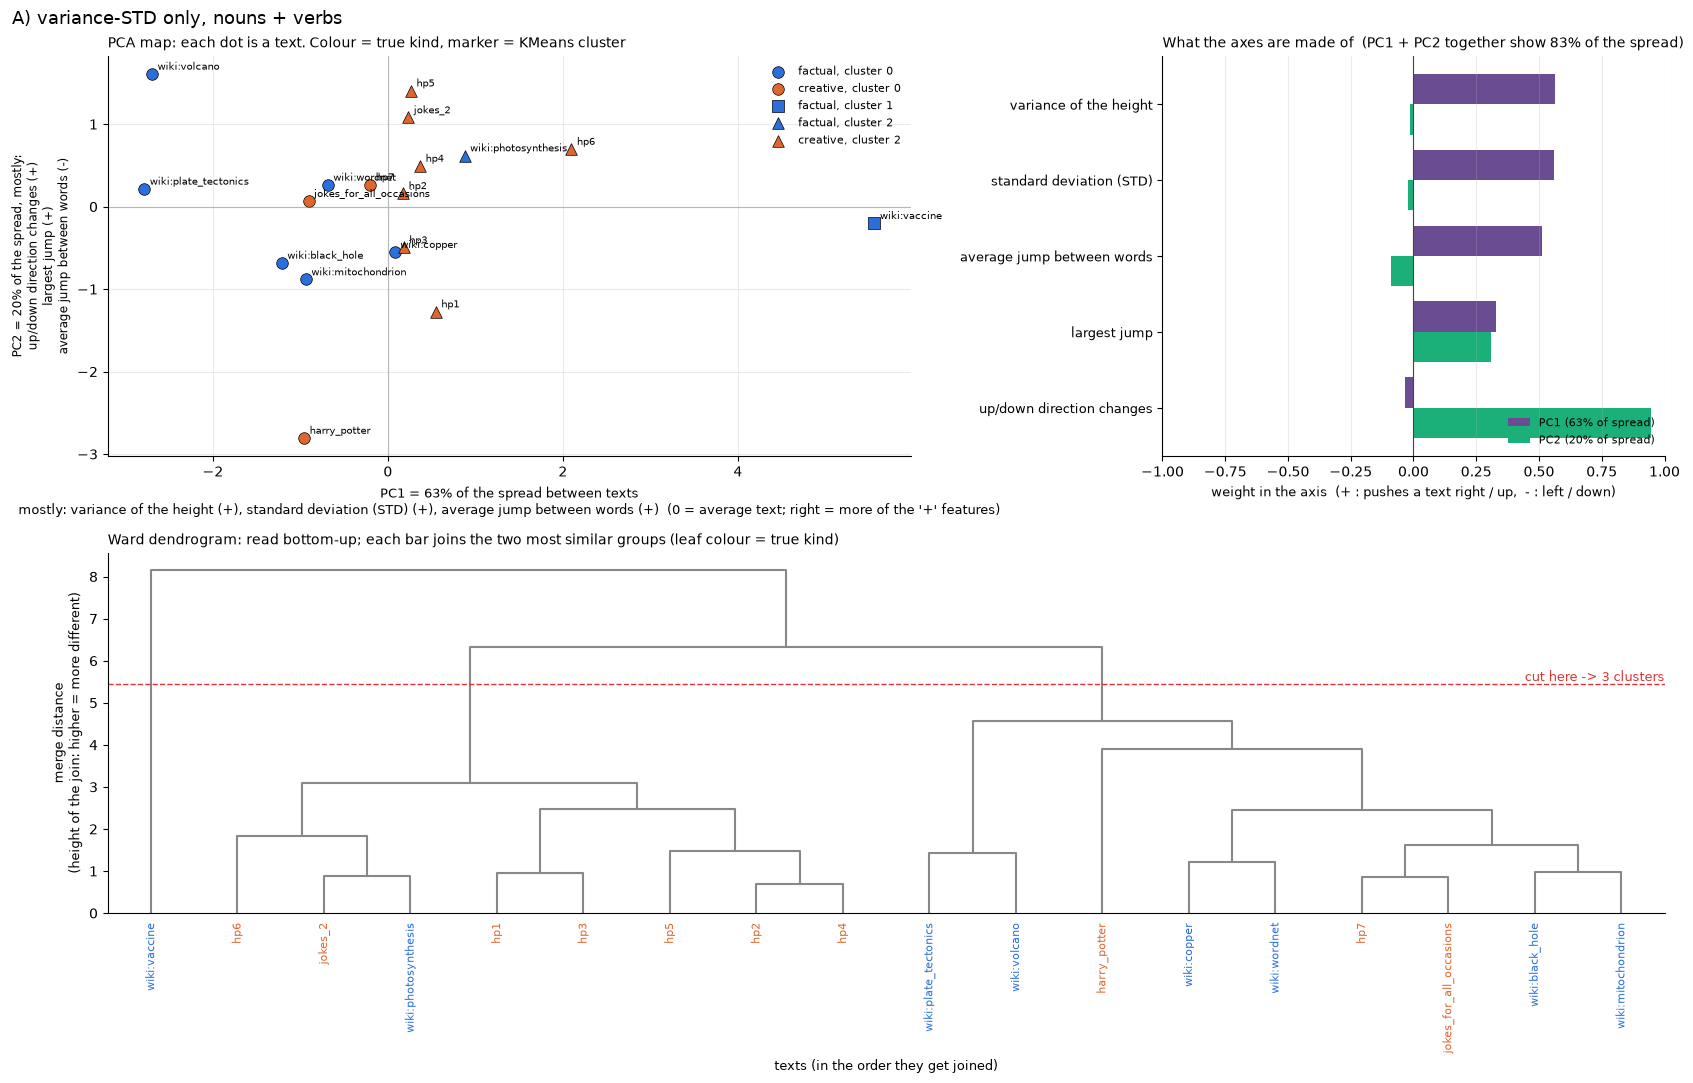

,PC1 (63%),PC2 (20%)
feature weight in axis,,
variance of the height,0.56,-0.01
standard deviation (STD),0.56,-0.02
average jump between words,0.51,-0.09
largest jump,0.33,0.31
up/down direction changes,-0.04,0.95


In [16]:
scores_A, clusters_A = cluster(texts_all, VAR_FEATS,k=3, title="A) variance-STD only, nouns + verbs")

## 4. Run B: all 6 shape features (nouns + verbs), k = 2 and k = 3
With k = 2, KMeans can use its second cluster on a single outlier (`wiki:vaccine` has a variance of about 9,
the rest about 3 to 6). k = 3 lets the outlier take its own cluster, so the other two can split the rest.

=== B2) all shape, nouns + verbs, k=2   (18 points, features: mean, var, mean_abs_jump, max_abs_jump, share_ge_8, direction_changes)


,ARI,purity,silhouette
KMeans,0.028,0.611,0.526
Ward,0.028,0.611,0.526


true kind,creative,factual
KMeans cluster,,
0,10,7
1,0,1


silhouette by k: {2: 0.526, 3: 0.247, 4: 0.242, 5: 0.288, 6: 0.244}


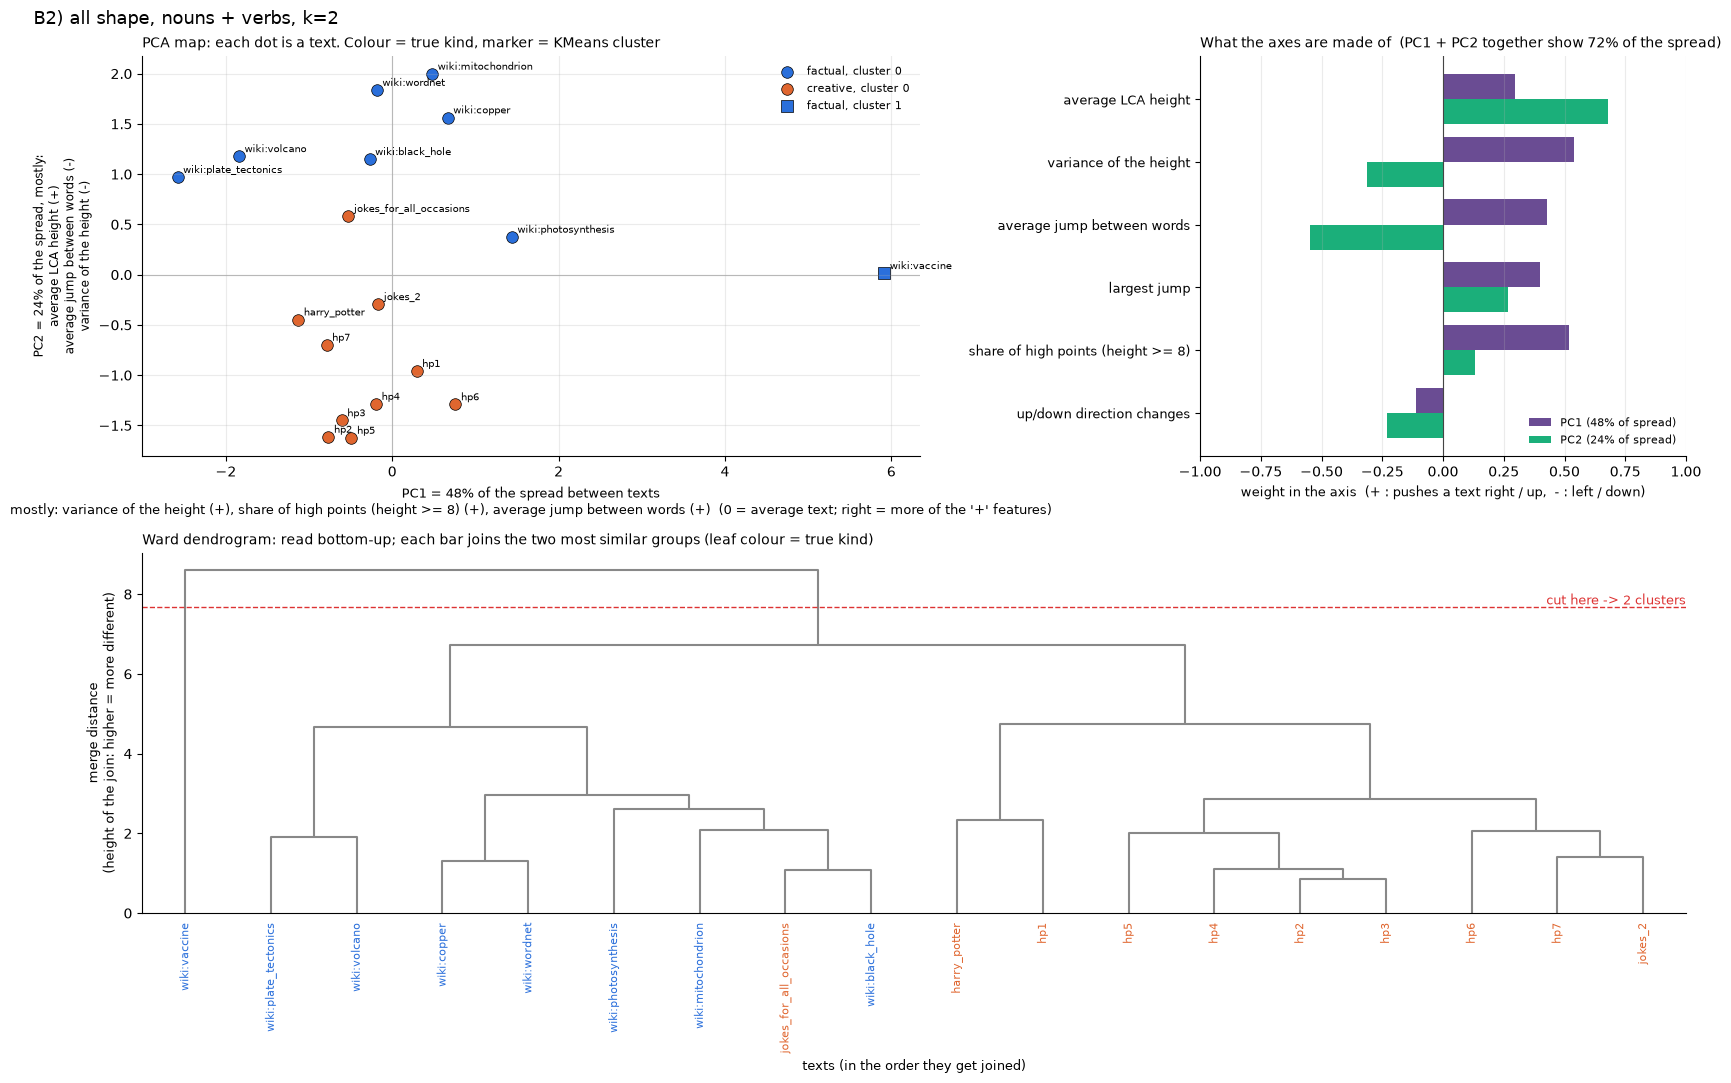

,PC1 (48%),PC2 (24%)
feature weight in axis,,
average LCA height,0.30,0.68
variance of the height,0.54,-0.31
average jump between words,0.43,-0.55
largest jump,0.40,0.27
share of high points (height >= 8),0.52,0.13
up/down direction changes,-0.11,-0.23


=== B3) all shape, nouns + verbs, k=3   (18 points, features: mean, var, mean_abs_jump, max_abs_jump, share_ge_8, direction_changes)


,ARI,purity,silhouette
KMeans,0.697,0.944,0.247
Ward,0.697,0.944,0.247


true kind,creative,factual
KMeans cluster,,
0,1,7
1,9,0
2,0,1


silhouette by k: {2: 0.526, 3: 0.247, 4: 0.242, 5: 0.288, 6: 0.244}


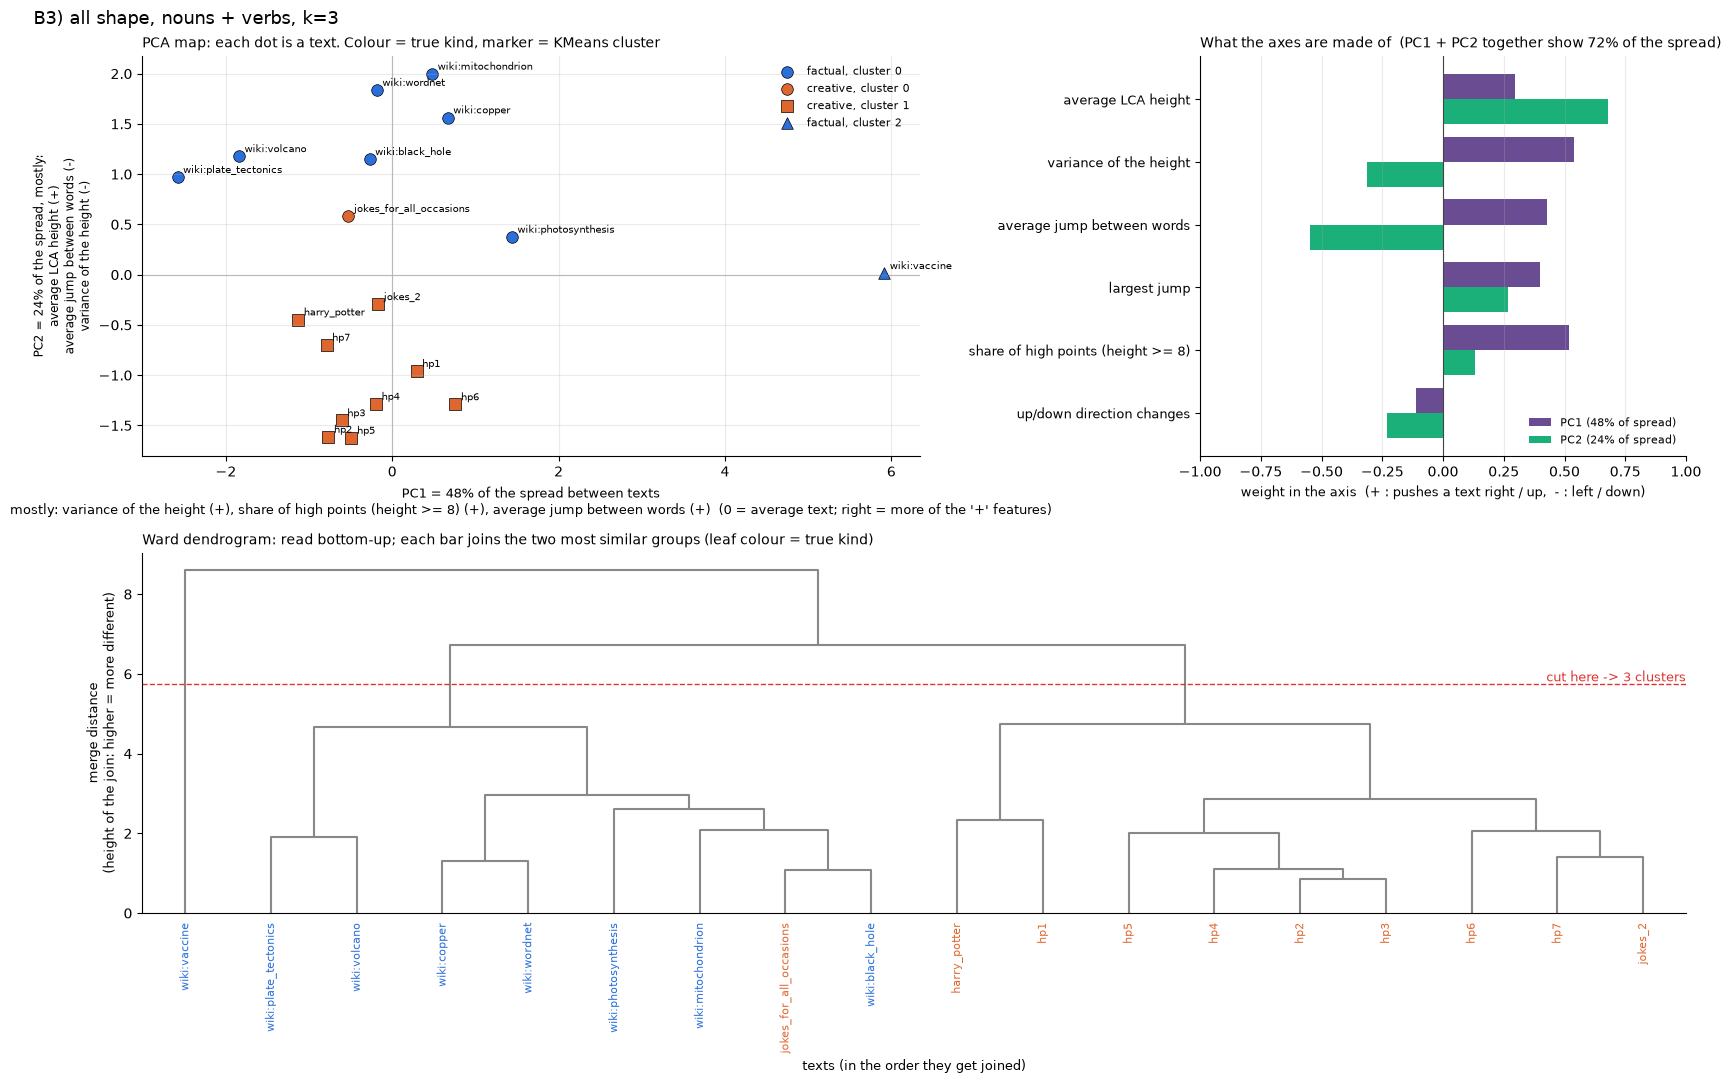

,PC1 (48%),PC2 (24%)
feature weight in axis,,
average LCA height,0.30,0.68
variance of the height,0.54,-0.31
average jump between words,0.43,-0.55
largest jump,0.40,0.27
share of high points (height >= 8),0.52,0.13
up/down direction changes,-0.11,-0.23


,text,kind,kmeans,ward
9,creative_jokes_for_all_occasions,creative,0,2
10,factual_wiki_black_hole,factual,0,2
11,factual_wiki_copper,factual,0,2
12,factual_wiki_mitochondrion,factual,0,2
13,factual_wiki_photosynthesis,factual,0,2
14,factual_wiki_plate_tectonics,factual,0,2
16,factual_wiki_volcano,factual,0,2
17,factual_wiki_wordnet,factual,0,2
0,creative_harry_potter,creative,1,0
1,creative_hp1,creative,1,0


In [17]:
scores_B2, clusters_B2 = cluster(texts_all, LCA_FEATS, k=2, title="B2) all shape, nouns + verbs, k=2")
scores_B3, clusters_B3 = cluster(texts_all, LCA_FEATS, k=3, title="B3) all shape, nouns + verbs, k=3")
clusters_B3.sort_values(["kmeans", "kind"])

## 5. Run C: all 6 shape features, nouns only, k = 3
Verbs sit about 3 levels lower in WordNet, and creative texts have about 2x as many verbs. If run B separates
the groups but this one doesn't, the clusters were mostly counting verbs, not measuring creativity.

=== C) all shape, nouns only, k=3   (18 points, features: mean, var, mean_abs_jump, max_abs_jump, share_ge_8, direction_changes)


,ARI,purity,silhouette
KMeans,0.040,0.667,0.193
Ward,0.139,0.722,0.249


true kind,creative,factual
KMeans cluster,,
0,0,1
1,3,4
2,7,3


silhouette by k: {2: 0.569, 3: 0.193, 4: 0.208, 5: 0.227, 6: 0.274}


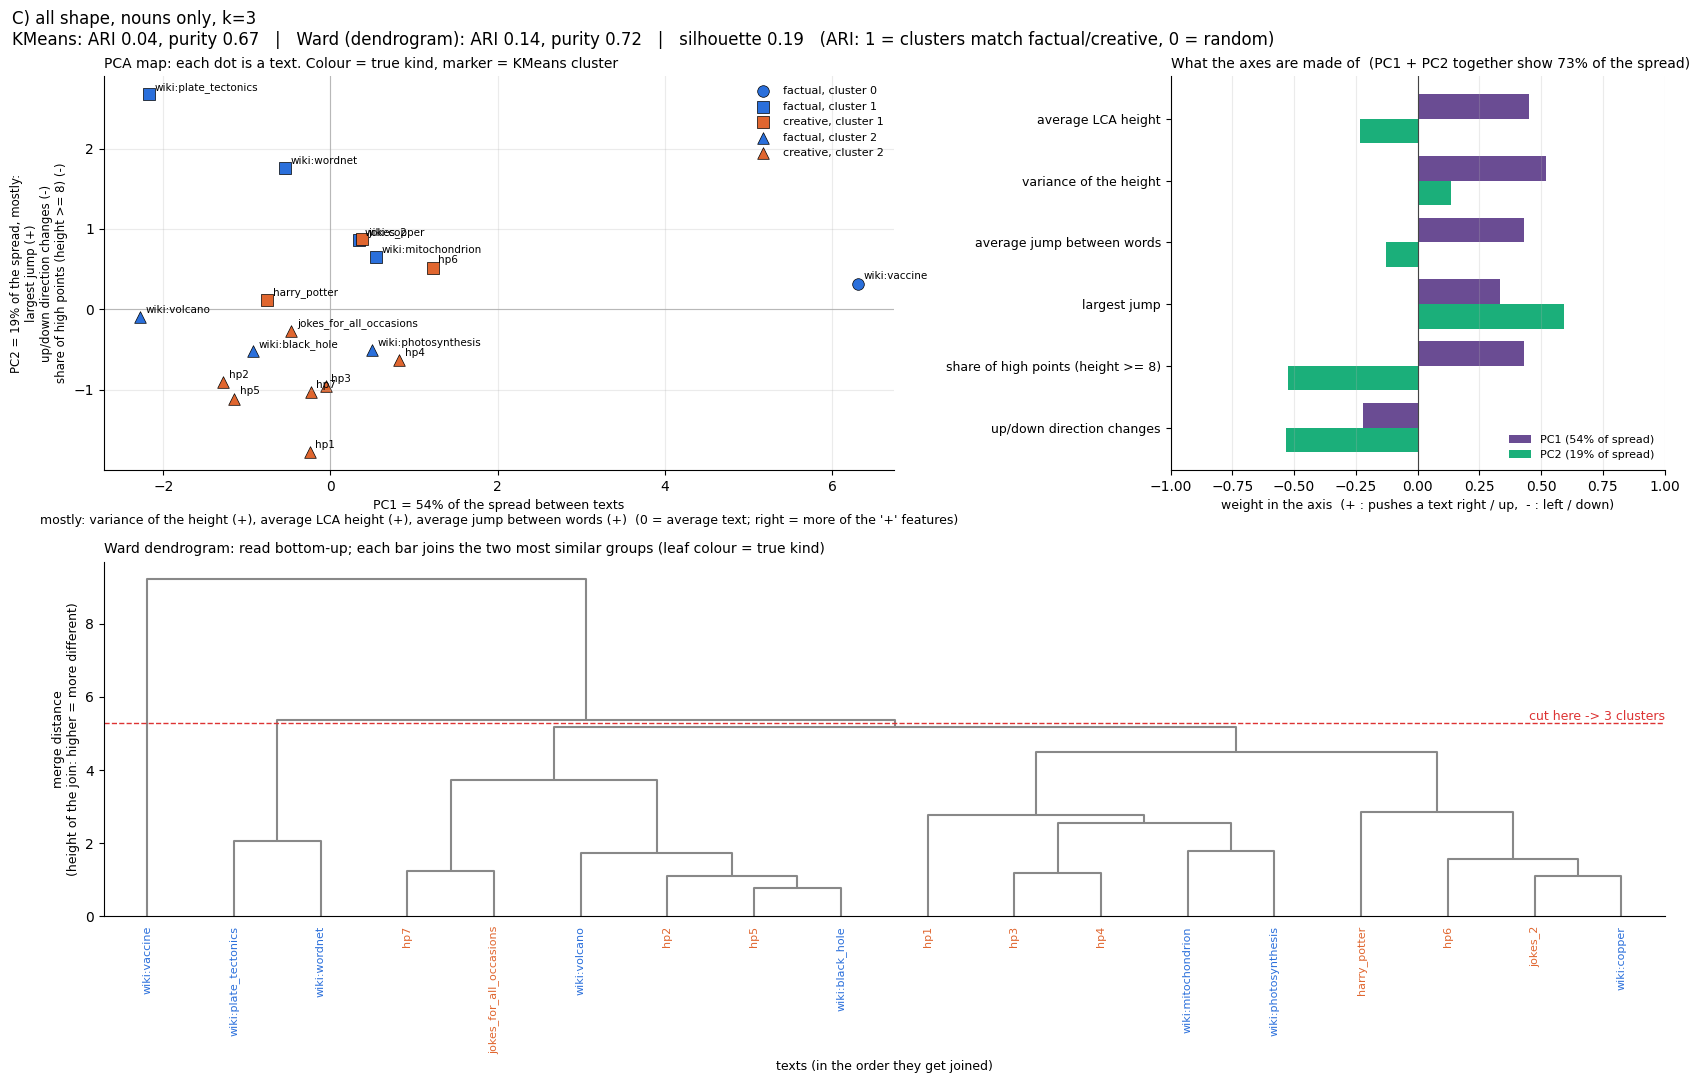

,PC1 (54%),PC2 (19%)
feature weight in axis,,
average LCA height,0.45,-0.23
variance of the height,0.52,0.14
average jump between words,0.43,-0.13
largest jump,0.33,0.59
share of high points (height >= 8),0.43,-0.53
up/down direction changes,-0.22,-0.53


In [6]:
texts_noun = per_text(pos="n")
scores_C, clusters_C = cluster(texts_noun, LCA_FEATS, k=3, title="C) all shape, nouns only, k=3")

## 6. Run D: model confidence only (nouns only), for comparison
Not LCA at all: just how sure the model was about the real word (`actual_word_prob`) and about its
top-k guesses (`cand_mass`). A baseline that shows how much the LCA features add on top of it.

=== D) confidence only, nouns only   (18 points, features: actual_word_prob, cand_mass)


,ARI,purity,silhouette
KMeans,1.000,1.000,0.449
Ward,0.777,0.944,0.443


true kind,creative,factual
KMeans cluster,,
0,10,0
1,0,8


silhouette by k: {2: 0.449, 3: 0.435, 4: 0.4, 5: 0.405, 6: 0.395}


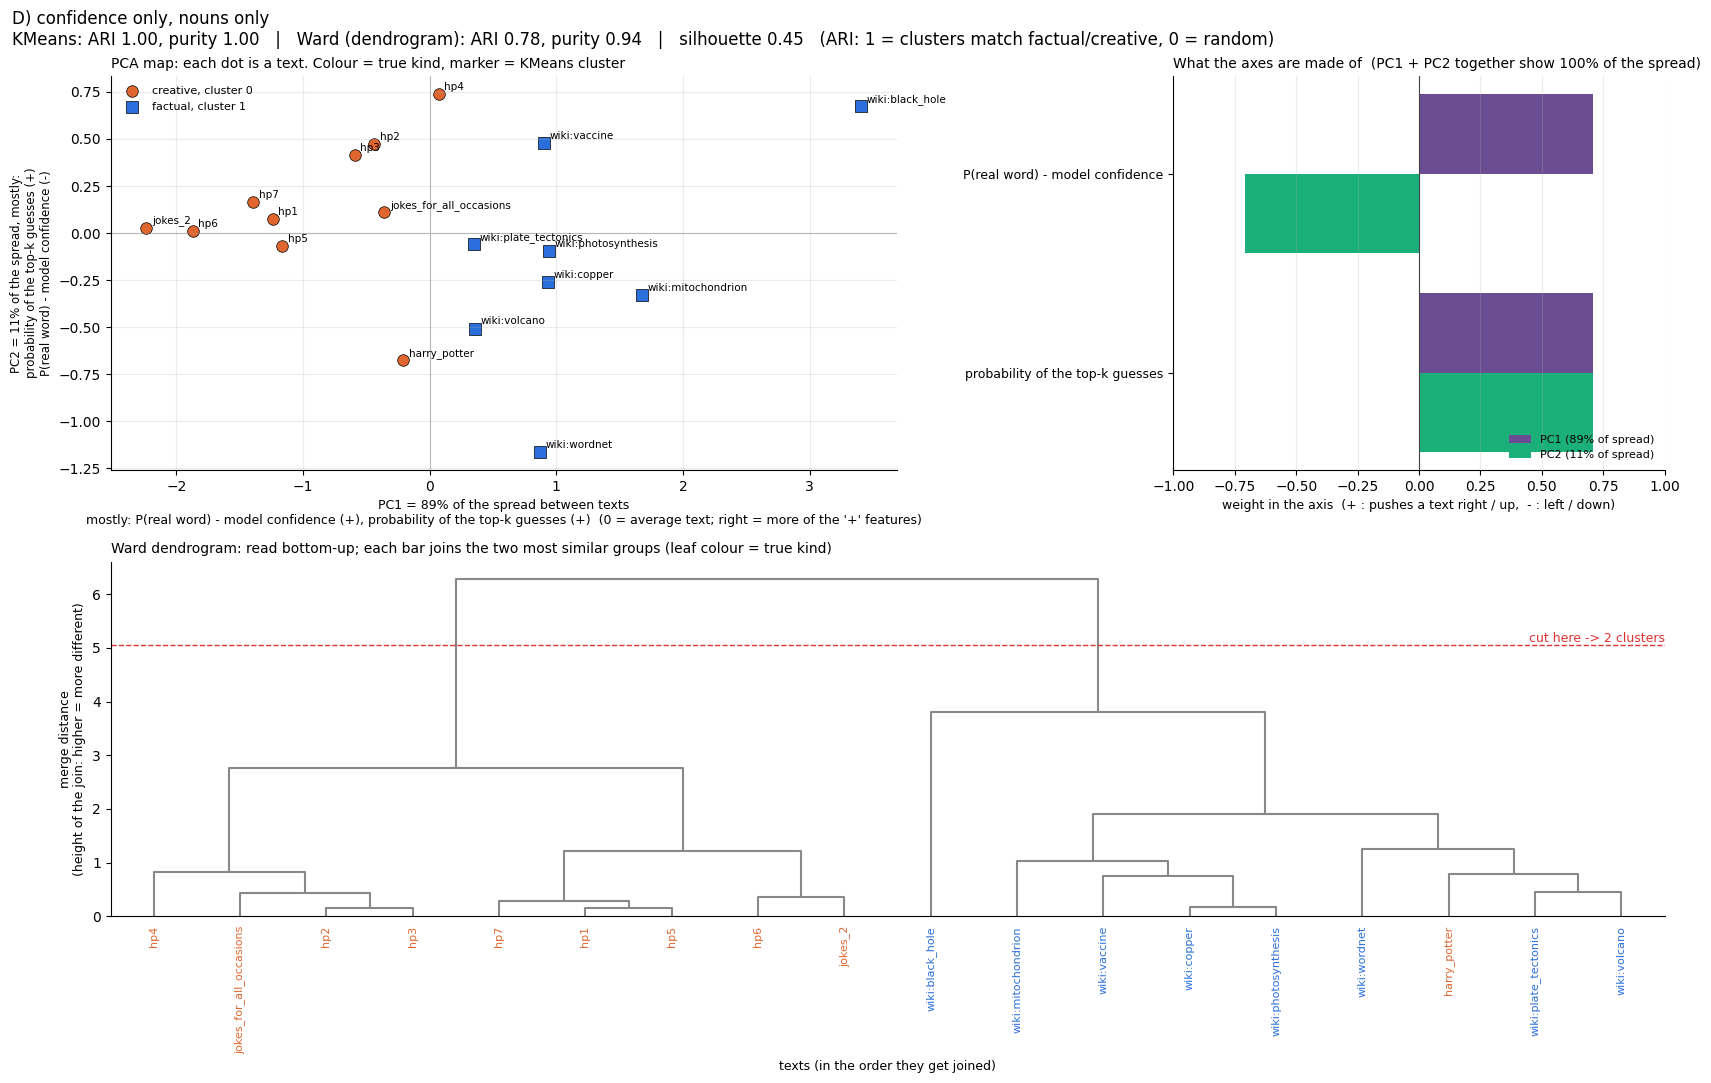

,PC1 (89%),PC2 (11%)
feature weight in axis,,
P(real word) - model confidence,0.71,-0.71
probability of the top-k guesses,0.71,0.71


In [7]:
scores_D, clusters_D = cluster(texts_noun, CONF_FEATS, title="D) confidence only, nouns only")

## 7. Run E: every model separately (54 points), all shape, k = 3
No averaging. If the clusters follow the text kind, all 3 copies of a text should land together; if they
follow the model, the models' own habits matter more than the text.

=== E) per model, nouns + verbs, k=3   (54 points, features: mean, var, mean_abs_jump, max_abs_jump, share_ge_8, direction_changes)


,ARI,purity,silhouette
KMeans,0.631,0.926,0.300
Ward,0.631,0.926,0.296


true kind,creative,factual
KMeans cluster,,
0,4,20
1,26,0
2,0,4


silhouette by k: {2: 0.484, 3: 0.3, 4: 0.315, 5: 0.277, 6: 0.288}


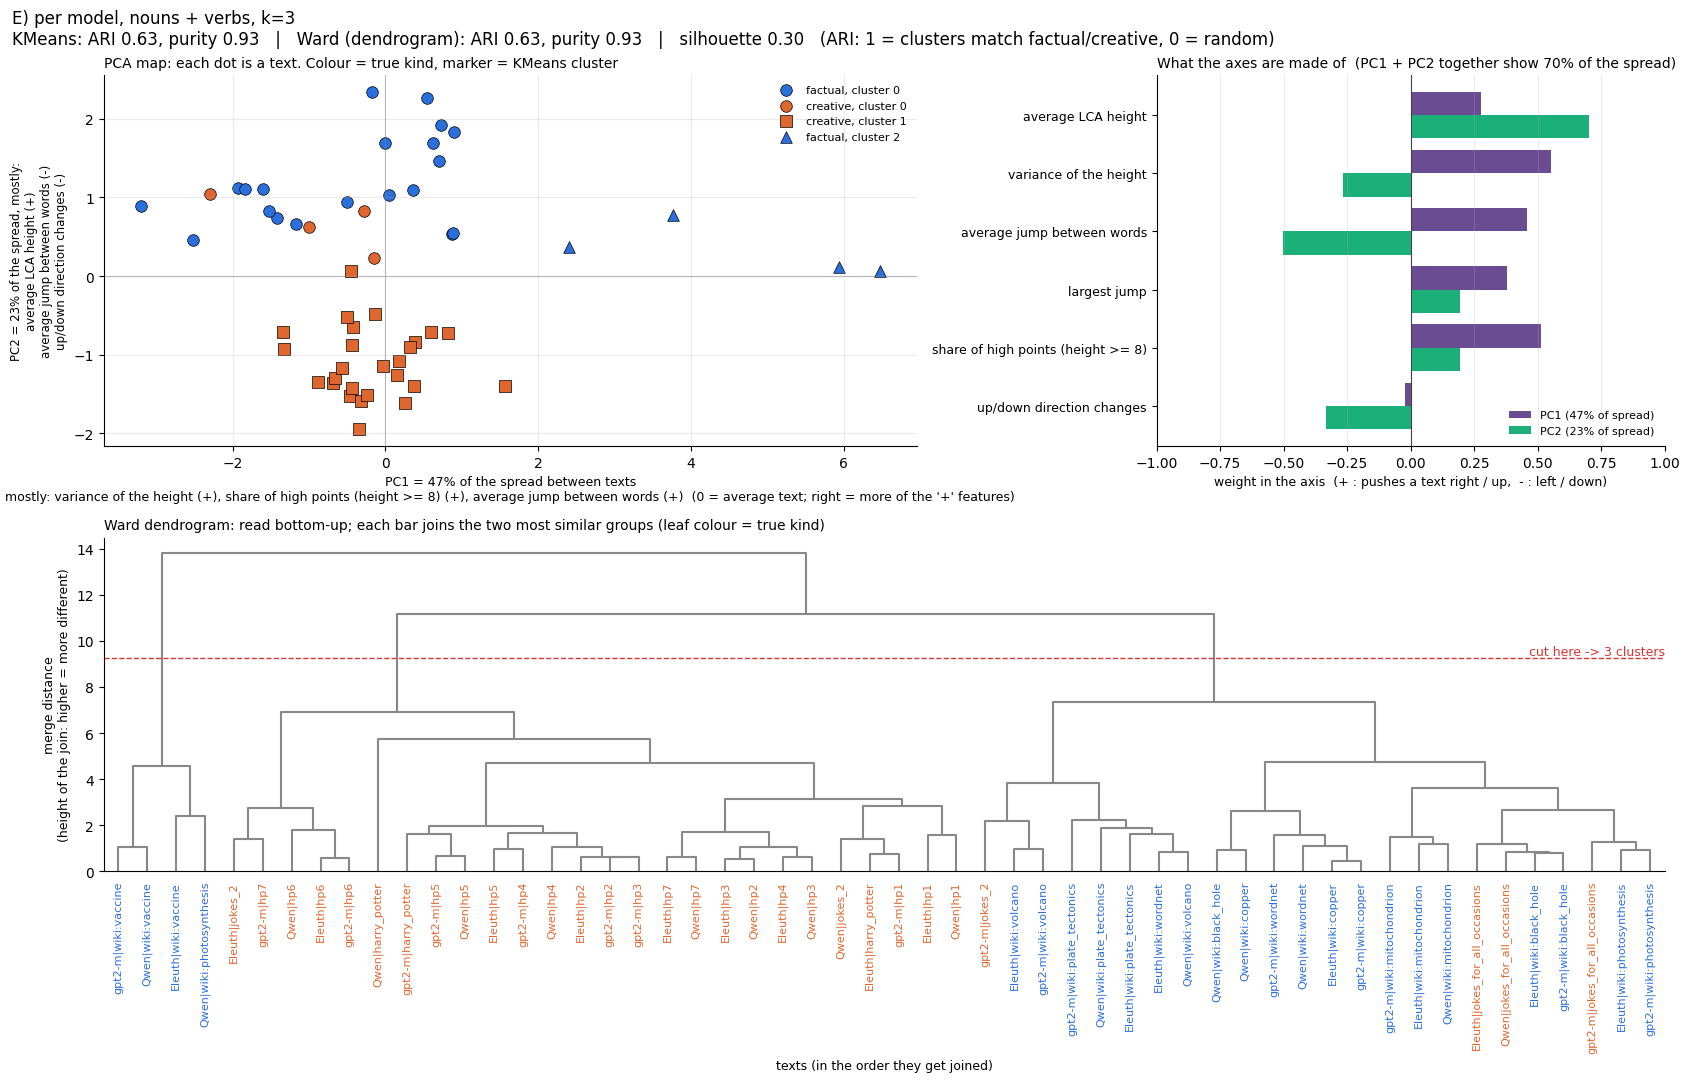

,PC1 (47%),PC2 (23%)
feature weight in axis,,
average LCA height,0.28,0.70
variance of the height,0.55,-0.27
average jump between words,0.46,-0.50
largest jump,0.38,0.19
share of high points (height >= 8),0.51,0.20
up/down direction changes,-0.02,-0.33


KMeans cluster vs model:


kmeans,0,1,2
model,,,
EleutherAI_pythia-410m,8,9,1
Qwen_Qwen2.5-1.5B,8,8,2
gpt2-medium,8,9,1


In [8]:
ft = feature_table(data)
ft["std"] = np.sqrt(ft["var"])
ft["point"] = ft["model"].str.split("_").str[0].str[:6] + "|" + ft["text"]
scores_E, clusters_E = cluster(ft, LCA_FEATS, k=3, title="E) per model, nouns + verbs, k=3", name_col="point")
print("KMeans cluster vs model:")
display(pd.crosstab(ft["model"], clusters_E["kmeans"]))

## 8. Run F: without `wiki:vaccine`, k = 2
In runs A and B2, k = 2 only split off `wiki:vaccine`, and runs B3/C/E used k = 3 to give it its own cluster.
Choosing k = 3 *after* seeing that is a hand-made choice. A cleaner test: remove the outlier and go back to
k = 2. If factual and creative still separate, the result doesn't depend on picking k.

=== F1) no vaccine, all shape, nouns + verbs, k=2   (17 points, features: mean, var, mean_abs_jump, max_abs_jump, share_ge_8, direction_changes)


,ARI,purity,silhouette
KMeans,0.558,0.882,0.266
Ward,0.764,0.941,0.264


true kind,creative,factual
KMeans cluster,,
0,9,1
1,1,6


silhouette by k: {2: 0.266, 3: 0.299, 4: 0.286, 5: 0.269, 6: 0.218}


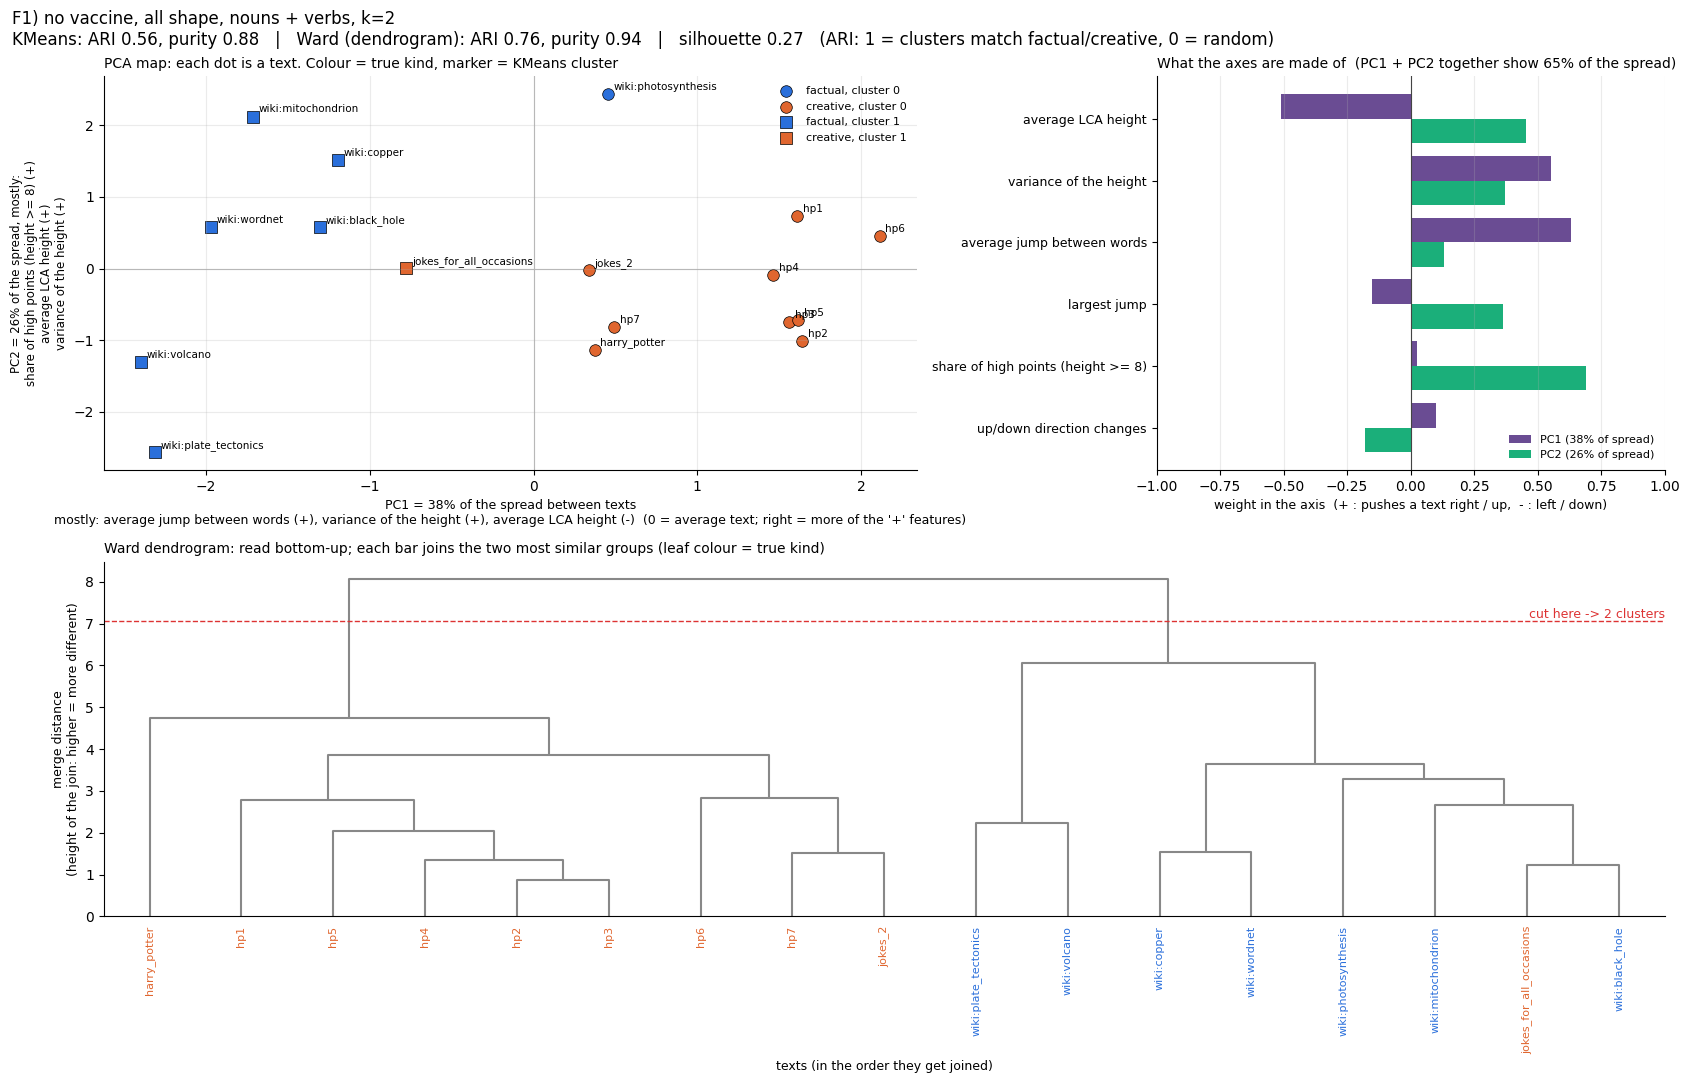

,PC1 (38%),PC2 (26%)
feature weight in axis,,
average LCA height,-0.51,0.45
variance of the height,0.55,0.37
average jump between words,0.63,0.13
largest jump,-0.15,0.36
share of high points (height >= 8),0.02,0.69
up/down direction changes,0.10,-0.18


,text,kind,kmeans,ward
9,creative_jokes_for_all_occasions,creative,1,0
10,factual_wiki_black_hole,factual,1,0
11,factual_wiki_copper,factual,1,0
12,factual_wiki_mitochondrion,factual,1,0
13,factual_wiki_photosynthesis,factual,0,0
14,factual_wiki_plate_tectonics,factual,1,0
15,factual_wiki_volcano,factual,1,0
16,factual_wiki_wordnet,factual,1,0
0,creative_harry_potter,creative,0,1
1,creative_hp1,creative,0,1


In [9]:
OUTLIER = "factual_wiki_vaccine"
scores_F1, clusters_F1 = cluster(texts_all[texts_all.text != OUTLIER].reset_index(drop=True), LCA_FEATS, k=2,
                                 title="F1) no vaccine, all shape, nouns + verbs, k=2")
clusters_F1.sort_values(["ward", "kind"])

=== F2) no vaccine, all shape, nouns only, k=2   (17 points, features: mean, var, mean_abs_jump, max_abs_jump, share_ge_8, direction_changes)


,ARI,purity,silhouette
KMeans,0.244,0.765,0.236
Ward,-0.061,0.588,0.189


true kind,creative,factual
KMeans cluster,,
0,10,4
1,0,3


silhouette by k: {2: 0.236, 3: 0.215, 4: 0.219, 5: 0.243, 6: 0.259}


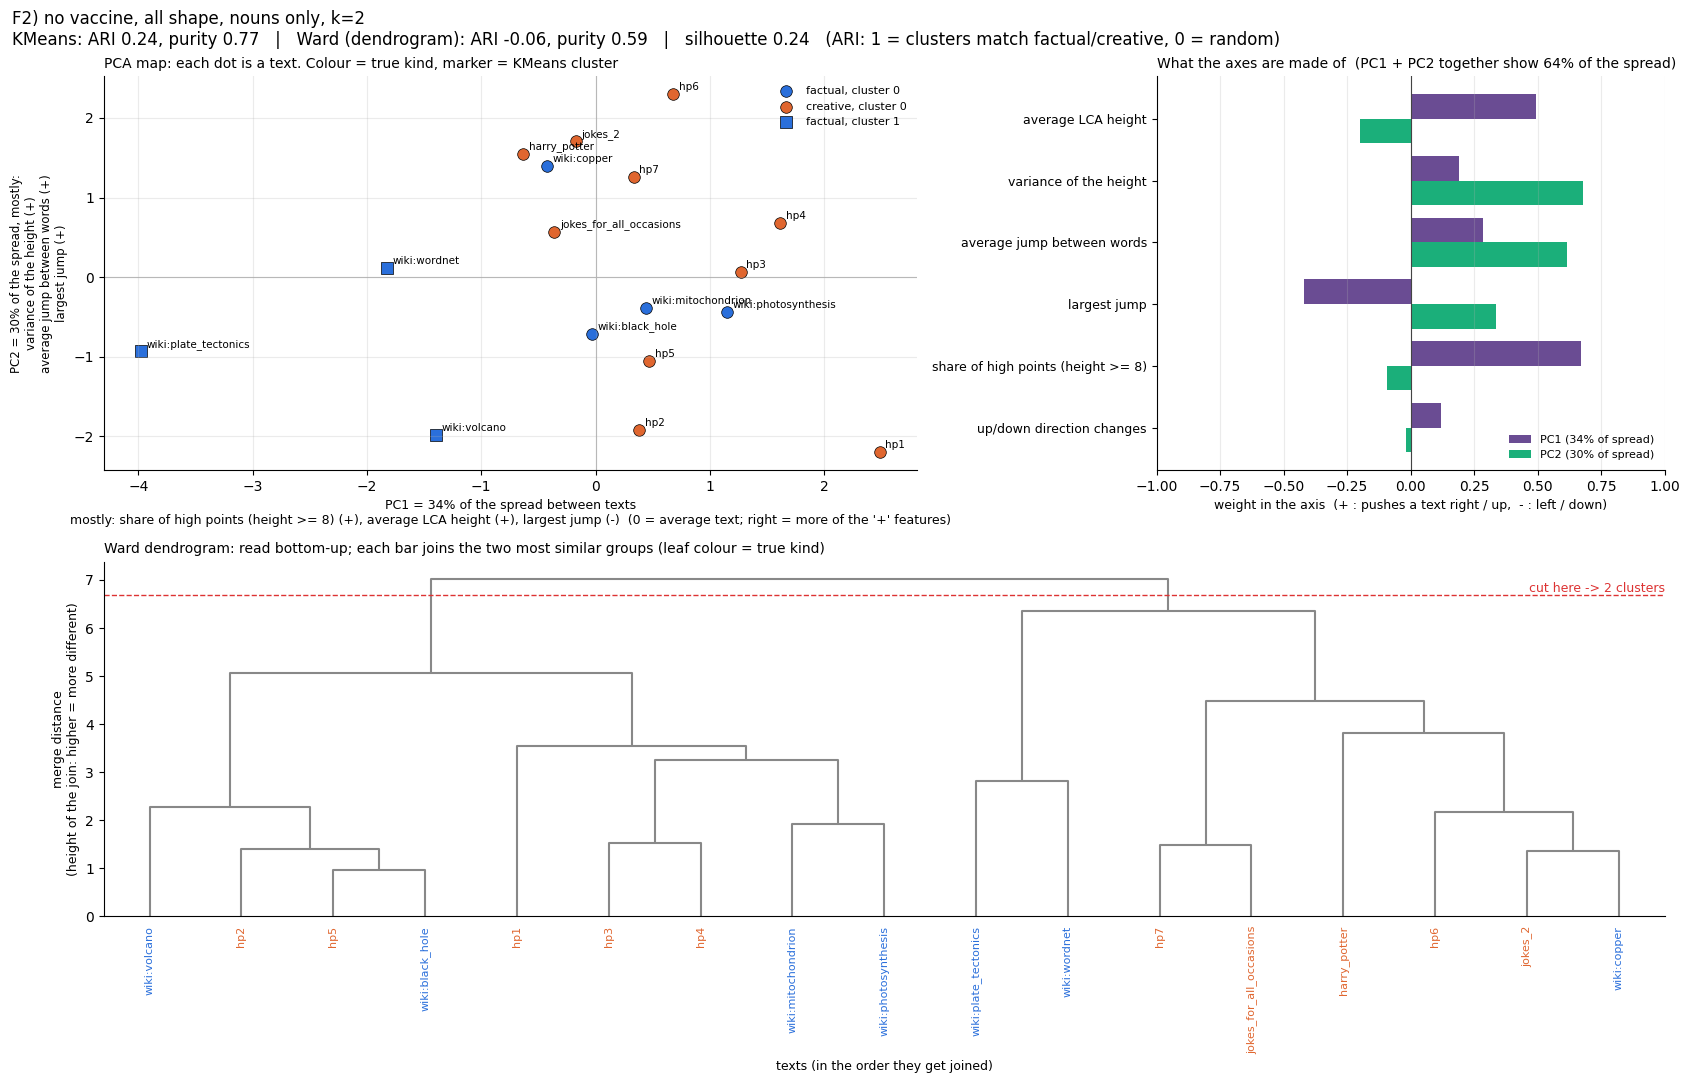

,PC1 (34%),PC2 (30%)
feature weight in axis,,
average LCA height,0.49,-0.20
variance of the height,0.19,0.68
average jump between words,0.28,0.61
largest jump,-0.42,0.34
share of high points (height >= 8),0.67,-0.09
up/down direction changes,0.12,-0.02


In [10]:
scores_F2, clusters_F2 = cluster(texts_noun[texts_noun.text != OUTLIER].reset_index(drop=True), LCA_FEATS, k=2,
                                 title="F2) no vaccine, all shape, nouns only, k=2")

## 9. Which features separate the groups?

In [11]:
def effect_sizes(table, feats):
    """Cohen's d (creative - factual) per feature: |d| > 0.8 is a large difference."""
    f, c = table[table.kind == "factual"], table[table.kind == "creative"]
    pooled = np.sqrt((f[feats].var() + c[feats].var()) / 2)
    return ((c[feats].mean() - f[feats].mean()) / pooled).round(2)


pd.DataFrame({"nouns + verbs": effect_sizes(texts_all, LCA_FEATS + ["std"] + CONF_FEATS),
              "nouns only": effect_sizes(texts_noun, LCA_FEATS + ["std"] + CONF_FEATS)}).rename(index=nice)

,nouns + verbs,nouns only
average LCA height,-3.02,-0.41
variance of the height,0.20,0.00
average jump between words,0.75,0.50
largest jump,-0.93,-1.26
share of high points (height >= 8),-0.68,0.23
up/down direction changes,0.27,0.77
standard deviation (STD),0.31,0.08
P(real word) - model confidence,-2.84,-3.00
probability of the top-k guesses,-2.25,-1.57


In [12]:
summary = pd.concat({"A: var/STD, all": scores_A, "B2: shape, all, k=2": scores_B2,
                     "B3: shape, all, k=3": scores_B3, "C: shape, nouns, k=3": scores_C,
                     "D: confidence, nouns": scores_D, "E: per model, k=3": scores_E,
                     "F1: no vaccine, all, k=2": scores_F1, "F2: no vaccine, nouns, k=2": scores_F2})
summary

ARI  purity  silhouette
A: var/STD, all            KMeans  0.028   0.611       0.550
                           Ward    0.028   0.611       0.550
B2: shape, all, k=2        KMeans  0.028   0.611       0.526
                           Ward    0.028   0.611       0.526
B3: shape, all, k=3        KMeans  0.697   0.944       0.247
                           Ward    0.697   0.944       0.247
C: shape, nouns, k=3       KMeans  0.040   0.667       0.193
                           Ward    0.139   0.722       0.249
D: confidence, nouns       KMeans  1.000   1.000       0.449
                           Ward    0.777   0.944       0.443
E: per model, k=3          KMeans  0.631   0.926       0.300
                           Ward    0.631   0.926       0.296
F1: no vaccine, all, k=2   KMeans  0.558   0.882       0.266
                           Ward    0.764   0.941       0.264
F2: no vaccine, nouns, k=2 KMeans  0.244   0.765       0.236
                           Ward   -0.061   0.588       0.189


## 10. Findings (`results/k5_clean`, 18 texts x 3 models)

**ARI**: 1 = clusters match factual/creative exactly, 0 = no better than random.

| run | features | ARI (KMeans) | what happened |
|---|---|---|---|
| A | variance / STD / jumps only | 0.03 | no split: the 2nd cluster is just `wiki:vaccine` |
| B2 | all 6 shape features, k=2 | 0.03 | same outlier problem |
| B3 | all 6 shape features, k=3 | **0.70** | vaccine alone; the other 17 split almost perfectly (only `jokes_for_all_occasions` lands with the wiki texts) |
| C | all 6 shape features, **nouns only**, k=3 | 0.04 | the split disappears |
| D | model confidence only (not LCA) | **1.00** | perfect split |
| E | per model (54 points), k=3 | 0.63 | all 3 models agree: clusters follow the text, not the model |
| F1 | all 6 shape features, **no vaccine**, k=2 | 0.56 (Ward **0.76**) | the split mostly holds without hand-picking k; only `jokes_for_all_occasions` (and `wiki:photosynthesis` for KMeans) land on the wrong side. But silhouette is low (0.27): two loose groups, not two tight ones |
| F2 | same, **nouns only** | 0.24 (Ward -0.06) | falls apart again |

1. **Variance and STD don't separate factual from creative.** Their effect size is about 0.2-0.3 (small). The
   creative curves are *not* jumpier than the factual ones in this data. `wiki:vaccine` is the most jumpy text of all.
2. **The split in run B3 comes from the level (`mean`), not the spread.** `mean` has the biggest effect
   (d = -3.0: creative is lower), and on nouns only it drops to -0.4, so the split vanishes (run C). This is
   the verb confound found in the main notebook: creative text has more verbs and verbs sit lower in WordNet.
3. **Model confidence separates the two kinds perfectly** (run D), even on nouns only. Models are much more sure
   on Wikipedia text. This isn't an LCA measure, but it's a useful baseline: an LCA feature only adds something
   if it helps on top of confidence.
4. **The 3 models behave the same** (run E): each cluster holds the same texts for every model.
5. **Removing the outlier (run F) confirms points 1-2.** Without `wiki:vaccine`, k = 2 finds factual vs creative
   on nouns + verbs, so the k = 3 result wasn't only due to hand-picking k. On nouns only it disappears again, so
   the split is still mostly the verb effect.

**Caveats:** 18 texts is small, so one outlier can change the result (see A/B2). The factual texts all come from
Wikipedia and the creative ones mostly from Harry Potter, so the clusters may be separating *sources* as much as
factual vs creative.

**Ideas to try next:** cluster 40-word windows instead of whole texts (many more points); remove the verb effect
by scoring each POS against its own baseline (z-score per POS) instead of dropping verbs; add factual texts that
aren't Wikipedia and creative texts that aren't Harry Potter.
